# Advanced LLM Fine Tuning · Lesson 03 · Audit preference pairs

How much of Direct Preference Optimisation's value comes from the quality of its labels?

You review records before they enter an accounts-payable queue. The synthetic remittance
advice below carries a printed total that differs from its arithmetic sum. Which of two
valid records should the model learn to prefer? Check the document, then compare that
decision with what the same model can extract from scratch.

**Run it.** Select a Tesla T4 and allow up to 30 minutes for setup, training and evaluation
(planning estimate). [Read the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/2-compare-training-stages/03-audit-preference-pairs).

## Runtime

Select a Tesla T4 in Colab. Each branch runs in sequence. Model downloads use the
public Hugging Face checkpoint, pinned by revision. The shared runtime can reuse
its weight cache. The material below embeds the invoice fixtures and training code.

In [1]:
import subprocess
import sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *['transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0']], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'transformers==4.51.3', 'peft==0.15.2', 'accelerate==1.6.0'], returncode=0)

In [2]:
import torch
if not torch.cuda.is_available() or "T4" not in torch.cuda.get_device_name(0):
    raise RuntimeError("Select a Tesla T4 runtime in Colab before running this notebook.")
print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)

GPU: Tesla T4
PyTorch: 2.14.1+cu130


In [3]:
from importlib.metadata import version

expected_versions = {"transformers": "4.51.3", "peft": "0.15.2", "accelerate": "1.6.0"}
versions = {name: version(name) for name in expected_versions}
if versions != expected_versions:
    raise RuntimeError(f"Restart the kernel with the pinned training stack. Found {versions}.")
print("Training packages:", versions)
get_ipython().run_line_magic("config", "InlineBackend.figure_formats = ['svg']")

Training packages: {'transformers': '4.51.3', 'peft': '0.15.2', 'accelerate': '1.6.0'}


## Invoice fixtures

The synthetic input and gold record come from a versioned scenario. The scorer compares
generated JSON with the gold record independently of model training. The release set stays
out of this lesson.

In [4]:
"""Versioned synthetic invoices and independent record scoring for the course."""

from __future__ import annotations

import json
import random
import re
from collections import Counter
from dataclasses import dataclass
from datetime import date, timedelta
from typing import Any

CATALOG_VERSION = "course-invoice-v1"
SPLIT_SIZES = {"train": 576, "dev": 72, "familiar": 96, "novel": 96, "independent": 48, "release": 120}
VISIBLE_CONTRACT = (
    "Extract exactly one JSON object with invoice_id, issued_on (YYYY-MM-DD), supplier, "
    "currency (ISO code), line_items (description, quantity, unit_minor), subtotal_minor, "
    "tax_minor, and total_minor. Preserve line order and convert currency amounts to integer cents. "
    "Use null only for a missing or ambiguous field. Do not rewrite printed amounts, invent fields, or add explanations."
)

@dataclass(frozen=True)
class Line:
    description: str
    quantity: int
    unit_minor: int


@dataclass(frozen=True)
class Invoice:
    key: str
    family: str
    supplier: str
    issued_on: str
    currency: str
    items: tuple[Line, ...]
    tax_minor: int | None
    locale: str
    split: str
    layout: str = "register"
    printed_total_minor: int | None = None


def invoice_record(invoice: Invoice) -> dict[str, Any]:
    subtotal = sum(line.quantity * line.unit_minor for line in invoice.items)
    total = subtotal + invoice.tax_minor if invoice.tax_minor is not None else None
    if invoice.printed_total_minor is not None:
        total = invoice.printed_total_minor
    return {
        "invoice_id": invoice.key,
        "issued_on": invoice.issued_on,
        "supplier": invoice.supplier,
        "currency": invoice.currency,
        "line_items": [
            {"description": item.description, "quantity": item.quantity, "unit_minor": item.unit_minor}
            for item in invoice.items
        ],
        "subtotal_minor": subtotal,
        "tax_minor": invoice.tax_minor,
        "total_minor": total,
    }


def make_catalog() -> list[Invoice]:
    rng = random.Random(20261126)
    sources = {
        "train": (24, ("register", "memo", "checkout", "ledger")),
        "dev": (6, ("register", "memo", "checkout", "ledger")),
        "familiar": (8, ("register", "memo", "checkout", "ledger")),
        "novel": (8, ("packing", "remittance", "service", "notice")),
        "independent": (4, ("separate",)),
        "release": (10, ("packing", "remittance", "service", "notice", "separate")),
    }
    locales = (("en-US", "USD"), ("en-GB", "GBP"), ("de-DE", "EUR"), ("fr-FR", "EUR"), ("en-US", "CAD"))
    services = ("Cooling filter", "Cable sleeve", "Bench calibration", "Door seal", "Grounding clip",
                "Rack inspection", "Meter label", "Packing insert", "Carrier adjustment", "Mounting plate")
    catalog = []
    seen_keys = set()
    supplier_codes = rng.sample(range(1000, 9999), sum(n for n, _ in sources.values()))
    supplier_index = 0
    for split, (family_count, layouts) in sources.items():
        for family_number in range(family_count):
            supplier_code = supplier_codes[supplier_index]
            supplier_index += 1
            layout = layouts[family_number % len(layouts)]
            family = f"{split}-{family_number:02d}"
            locale, currency = locales[family_number % len(locales)]
            for row in range(SPLIT_SIZES[split] // family_count):
                code = f"SF-{rng.randrange(100000, 1000000)}"
                while code in seen_keys:
                    code = f"SF-{rng.randrange(100000, 1000000)}"
                seen_keys.add(code)
                items = tuple(
                    Line(kind, rng.randint(1, 9), rng.randrange(200, 24800))
                    for kind in rng.sample(services, rng.randrange(1, 4))
                )
                subtotal = sum(x.quantity * x.unit_minor for x in items)
                tax = (subtotal * (7 if currency == "USD" else 13) + 50) // 100
                if split in {"novel", "independent", "release"} and row % 12 == 4:
                    tax = None
                displayed = subtotal + tax + 101 if tax is not None and row % 12 == 7 else None
                issued_on = (date(2025, 1, 1) + timedelta(days=rng.randint(0, 590))).isoformat()
                catalog.append(Invoice(code, family, f"Sample Supplier {supplier_code}", issued_on,
                                       currency, items, tax, locale, split, layout, displayed))
    return catalog


def formatted_money(minor: int | None, locale: str) -> str:
    if minor is None:
        return "-"
    dollars, cents = divmod(minor, 100)
    number = f"{dollars:,}.{cents:02d}"
    if locale == "de-DE":
        return number.replace(",", "_").replace(".", ",").replace("_", ".")
    if locale == "fr-FR":
        return number.replace(",", " ").replace(".", ",")
    return number


def invoice_text(invoice: Invoice) -> str:
    gold = invoice_record(invoice)
    money = lambda value: formatted_money(value, invoice.locale)
    identifier = f"{invoice.key}"
    supplier = invoice.supplier
    issued = invoice.issued_on
    currency = invoice.currency
    subtotal = money(gold["subtotal_minor"])
    tax = money(gold["tax_minor"])
    total = money(gold["total_minor"])
    register = [f"{row.description} | {row.quantity} | {money(row.unit_minor)}" for row in invoice.items]
    inline = [f"{row.quantity} x {row.description} @ {money(row.unit_minor)} per unit" for row in invoice.items]
    service = [f"{row.description}: {money(row.unit_minor)} each for {row.quantity} units" for row in invoice.items]
    if invoice.layout == "register":
        return "\n".join([f"Supplier: {supplier}", f"Invoice: {identifier}", f"Issued: {issued}", f"Currency: {currency}",
                          "Description | Quantity | Unit price", *register,
                          f"Subtotal: {subtotal}", f"Tax: {tax}", f"Amount due: {total}"])
    if invoice.layout == "memo":
        return "\n".join([f"{supplier} billing memo / {issued}", f"Account invoice {identifier} [{currency}]",
                          *inline, f"Total due {total} including tax {tax}; net amount {subtotal}."])
    if invoice.layout == "checkout":
        return "\n".join([f"{identifier} / supplier {supplier}", f"Date of issue {issued} / All amounts {currency}",
                          *service, f"Net {subtotal}", f"Sales tax {tax}", f"Payable {total}"])
    if invoice.layout == "ledger":
        return "\n".join([f"{supplier} | issued {issued} | invoice {identifier}", f"Ledger in {currency}",
                          "Service | Count | Per unit", *register, f"Before tax {subtotal}",
                          f"Tax charged {tax}", f"Balance {total}"])
    if invoice.layout == "packing":
        return "\n".join([f"Billing details / {identifier}", f"Sold by {supplier}", f"Document date {issued}",
                          f"Invoice currency {currency}", f"Balance payable {total}", *service,
                          f"Merchandise {subtotal}", f"Tax {tax}"])
    if invoice.layout == "remittance":
        return "\n".join([f"Remittance advice for {identifier} ({currency})", f"{supplier} / Document issued {issued}",
                          f"Pay this amount {total}", *inline, f"Net charges {subtotal} / Tax {tax}"])
    if invoice.layout == "service":
        return "\n".join([f"Ref {identifier} / {currency}", f"Service fee notice, {issued}", supplier,
                          *[f"Unit {money(row.unit_minor)} / {row.quantity} times / {row.description}" for row in invoice.items],
                          f"Fee subtotal {subtotal}", f"Plus tax {tax}", f"Amount requested {total}"])
    if invoice.layout == "notice":
        return "\n".join([f"{supplier} / statement {identifier}", f"Issued on {issued}",
                          f"Invoice denomination {currency}", "One-off charges", *service,
                          f"Pre-tax {subtotal} / Tax assessment {tax} / Final bill {total}"])
    return "\n".join([f"Document {identifier}", f"Biller {supplier} / As of {issued} / {currency}", *inline,
                      f"Gross {total}", f"Breakdown: net {subtotal} and taxes {tax}."])


def _strict_dict(pairs: list[tuple[str, Any]]) -> dict[str, Any]:
    result: dict[str, Any] = {}
    for key, value in pairs:
        if key in result:
            raise ValueError(f"Duplicate JSON key {key!r}")
        result[key] = value
    return result


def parse_record(completion: str | dict[str, Any]) -> dict[str, Any] | None:
    if isinstance(completion, str):
        try:
            data = json.loads(completion, object_pairs_hook=_strict_dict)
        except (ValueError, TypeError, RecursionError):
            return None
    else:
        data = completion
    keys = {"invoice_id", "issued_on", "supplier", "currency", "line_items", "subtotal_minor", "tax_minor", "total_minor"}
    if not isinstance(data, dict) or set(data) != keys:
        return None
    for name in ("invoice_id", "supplier", "issued_on", "currency"):
        value = data[name]
        if value is not None and (not isinstance(value, str) or not value.strip()):
            return None
    try:
        if data["issued_on"] is not None and date.fromisoformat(data["issued_on"]).isoformat() != data["issued_on"]:
            return None
    except ValueError:
        return None
    if data["currency"] is not None and re.fullmatch("[A-Z]{3}", data["currency"]) is None:
        return None
    for name in ("subtotal_minor", "tax_minor", "total_minor"):
        if data[name] is not None and type(data[name]) is not int:
            return None
    if not isinstance(data["line_items"], list):
        return None
    for row in data["line_items"]:
        if not isinstance(row, dict) or set(row) != {"description", "quantity", "unit_minor"}:
            return None
        if type(row["description"]) is not str or type(row["quantity"]) is not int or type(row["unit_minor"]) is not int:
            return None
        if not row["description"].strip() or row["quantity"] <= 0:
            return None
    return data


def score_record(completion: str | dict[str, Any], invoice: Invoice) -> dict[str, Any]:
    truth = invoice_record(invoice)
    observed = parse_record(completion)
    field_correct = {key: observed is not None and observed.get(key) == value
                     for key, value in truth.items() if key != "line_items"}
    keys = ("description", "quantity", "unit_minor")
    expected = Counter(tuple(r[k] for k in keys) for r in truth["line_items"])
    predicted = Counter(tuple(r[k] for k in keys) for r in observed["line_items"]) if observed is not None else Counter()
    matches = (expected & predicted).total()
    row_count = expected.total() + predicted.total()
    return {"valid": observed is not None, "exact": observed == truth,
            "fields": sum(field_correct.values()) / len(field_correct), "field_correct": field_correct,
            "row_f1": 2 * matches / row_count if row_count else 1.0}


def rules_extract(text: str) -> dict[str, Any] | None:
    lines = text.splitlines()
    if len(lines) < 9 or lines[4] != "Description | Quantity | Unit price":
        return None
    property_names = ("supplier", "invoice_id", "issued_on", "currency")
    headers = ("Supplier: ", "Invoice: ", "Issued: ", "Currency: ")
    if any(not line.startswith(header) for line, header in zip(lines, headers)):
        return None
    data = {name: line.removeprefix(header) for name, line, header in zip(property_names, lines, headers)}

    def minor(text_amount: str) -> int | None:
        if text_amount == "-":
            return None
        if re.fullmatch(r"(?:\d+|\d{1,3}(?:[., ]\d{3})+)[.,]\d{2}", text_amount) is None:
            raise ValueError("Unsupported amount format")
        units, frac = text_amount[:-3], text_amount[-2:]
        return int(re.sub(r"\D", "", units)) * 100 + int(frac)

    try:
        rows = [line.split(" | ") for line in lines[5:-3]]
        data["line_items"] = [{"description": desc, "quantity": int(qty), "unit_minor": minor(unit)}
                              for desc, qty, unit in rows]
        data["subtotal_minor"] = minor(lines[-3].removeprefix("Subtotal: "))
        data["tax_minor"] = minor(lines[-2].removeprefix("Tax: "))
        data["total_minor"] = minor(lines[-1].removeprefix("Amount due: "))
    except ValueError:
        return None
    return parse_record(data)


def examples_for(split: str, limit: int | None = None) -> list[Invoice]:
    found = [invoice for invoice in make_catalog() if invoice.split == split]
    if not found:
        raise ValueError(f"Unknown invoice split {split!r}")
    if limit is None or limit >= len(found):
        return found
    if limit <= 0:
        raise ValueError("Limit must be positive")
    groups: dict[str, list[Invoice]] = {}
    for invoice in found:
        groups.setdefault(invoice.family, []).append(invoice)
    balanced = [invoice for group_rows in zip(*groups.values(), strict=True) for invoice in group_rows]
    return balanced[:limit]

## Completion masking

The prefix-stable masking and preference helpers below adapt Apache-2.0 recipe code from
the Together Post-Training Cookbook. The shared helpers build a causal training sequence
while marking just the answer tokens and end marker as targets.

In [5]:
# SPDX-License-Identifier: Apache-2.0
"""Portable training functions from the Together Post-Training Cookbook.

Adapted from togethercomputer/post-training-cookbook at
226e03ca225d6f13434047cf0f45ab3070a29801. See third_party for the Apache licence
and the original paths. The hosted training and provisioning code is replaced
by notebook-local PyTorch and typed fixtures.
"""

from __future__ import annotations

import random
from collections import Counter
from collections.abc import Callable, Iterable, Sequence
from dataclasses import dataclass, field
from typing import NamedTuple, TypeVar

import torch
import torch.nn.functional as F


class Turn(NamedTuple):
    prompt: list[int]
    completion: list[int]


class MaskedSequence(NamedTuple):
    input_ids: list[int]
    completion_mask: list[int]


def split_turns(turns: Iterable[Turn]) -> list[MaskedSequence]:
    """Build prefix-stable sequences with a token-aligned completion mask."""
    sequences: list[MaskedSequence] = []
    emitted: list[int] = []
    mask: list[int] = []
    for prompt, completion in turns:
        if len(prompt) < len(emitted) or prompt[: len(emitted)] != emitted:
            if emitted:
                sequences.append(MaskedSequence(emitted, mask))
            mask = [0] * len(prompt)
        else:
            mask = mask + [0] * (len(prompt) - len(emitted))
        emitted = prompt + completion
        mask = mask + [1] * len(completion)
    if emitted:
        sequences.append(MaskedSequence(emitted, mask))
    return sequences


def masked_logp_sum(logprobs: torch.Tensor, mask: Sequence[float]) -> torch.Tensor:
    """Sum target-aligned response log probabilities and retain gradients."""
    if logprobs.ndim != 1 or len(mask) != logprobs.shape[0]:
        raise ValueError("The response mask must match the one-dimensional target log probabilities.")
    weights = torch.as_tensor(mask, dtype=logprobs.dtype, device=logprobs.device)
    return (logprobs * weights).sum()


def make_dpo_loss(
    ref_sums: Sequence[float],
    masks: Sequence[Sequence[float]],
    *,
    beta: float,
    label_smoothing: float = 0.0,
) -> Callable[[Sequence[torch.Tensor]], torch.Tensor]:
    """Close over fixed reference scores and response masks for chosen/rejected pairs."""
    if not ref_sums or len(ref_sums) != len(masks) or len(ref_sums) % 2:
        raise ValueError("Supply at least one complete pair and one mask for each reference score.")
    if beta <= 0.0 or not 0.0 <= label_smoothing <= 0.5:
        raise ValueError("Beta must be positive and label smoothing must be between 0 and 0.5.")
    branch_size = len(ref_sums)

    def loss_fn(policy_logprobs: Sequence[torch.Tensor]) -> torch.Tensor:
        if len(policy_logprobs) != branch_size:
            raise ValueError(f"Expected {branch_size} policy log-probability tensors.")
        policy = torch.stack([masked_logp_sum(values, mask) for values, mask in zip(policy_logprobs, masks, strict=True)])
        reference = policy.new_tensor(ref_sums)
        delta = policy - reference
        margin = beta * (delta[0::2] - delta[1::2])
        return (-(1.0 - label_smoothing) * F.logsigmoid(margin) - label_smoothing * F.logsigmoid(-margin)).mean()

    return loss_fn


def compute_overlong_penalty(
    response_length: int,
    max_response_length: int,
    overlong_buffer_len: int,
    penalty_factor: float = 1.0,
) -> float:
    """Apply the cookbook's DAPO soft penalty near a generation cap."""
    if overlong_buffer_len <= 0:
        return 0.0
    expected_len = max_response_length - overlong_buffer_len
    exceed_len = response_length - expected_len
    return min(-exceed_len / overlong_buffer_len * penalty_factor, 0.0)


Item = TypeVar("Item")


def oversample_until_kept(
    draw_batch: Callable[[], Iterable[Item]],
    *,
    is_kept: Callable[[Item], bool],
    target: int,
    max_attempts: int,
) -> tuple[list[Item], int]:
    """Keep rejected groups in the audit trail while bounding draws."""
    if target <= 0 or max_attempts <= 0:
        raise ValueError("Target and maximum attempts must be positive.")
    items: list[Item] = []
    kept = 0
    for attempts in range(1, max_attempts + 1):
        for item in draw_batch():
            items.append(item)
            if is_kept(item):
                kept += 1
                if kept >= target:
                    return items, attempts
    return items, max_attempts


@dataclass(frozen=True)
class TeacherRequest:
    key: str
    messages: Sequence[dict[str, str]]
    meta: dict[str, object] = field(default_factory=dict)


@dataclass(frozen=True)
class TeacherOutput:
    content: str
    ok: bool = True
    truncated: bool = False


def sft_rows(
    requests: Sequence[TeacherRequest],
    outputs: dict[str, TeacherOutput],
    *,
    reject_reason: Callable[[TeacherRequest, TeacherOutput], str | None] | None = None,
) -> tuple[list[dict[str, object]], Counter[str]]:
    """Convert verified procedural teacher outputs to SFT rows and count exclusions."""
    rows: list[dict[str, object]] = []
    dropped: Counter[str] = Counter()
    for request in requests:
        output = outputs.get(request.key)
        if output is None:
            dropped["missing"] += 1
            continue
        if not output.ok:
            dropped["failed"] += 1
            continue
        if output.truncated:
            dropped["truncated"] += 1
            continue
        content = output.content.strip()
        if not content:
            dropped["empty"] += 1
            continue
        reason = reject_reason(request, output) if reject_reason is not None else None
        if reason is not None:
            dropped[reason] += 1
            continue
        assistant = {"role": "assistant", "content": content}
        rows.append({"id": request.key, "messages": [*request.messages, assistant], "meta": dict(request.meta)})
    return rows, dropped


def mix(*groups: Sequence[Item], seed: int = 0) -> list[Item]:
    """Concatenate row groups and shuffle them deterministically."""
    rows = [row for group in groups for row in group]
    random.Random(seed).shuffle(rows)
    return rows

## Training and scoring

A common prompt, batch schedule and scorer make each comparison interpretable. The paired
uncertainty calculation resamples whole layout families, so repeated layouts do not count
as independent evidence.

In [6]:
"""Shared notebook-local text training and measurement for lessons 01–03."""
from __future__ import annotations

import gc
import hashlib
import importlib.metadata
import json
import random
import statistics
import time
from collections import defaultdict
from pathlib import Path

import torch

MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"
SEED = 42
MAX_TOKENS = 1536
MAX_NEW_TOKENS = 384
BATCH = 2



def canonical_json(record):
    return json.dumps(record, ensure_ascii=False, separators=(",", ":"))


def ordered_by_family(items):
    by_family = defaultdict(list)
    for invoice in items:
        by_family[invoice.family].append(invoice)
    randomizer = random.Random(SEED)
    families = list(by_family)
    randomizer.shuffle(families)
    for rows in by_family.values():
        randomizer.shuffle(rows)
    return [
        by_family[family][offset]
        for offset in range(max(map(len, by_family.values()), default=0))
        for family in families
        if offset < len(by_family[family])
    ]


def lesson_prompts(catalog):
    """Choose one training exemplar and preserve dataset order after seeded sampling."""
    train = ordered_by_family([invoice for invoice in catalog if invoice.split == "train"])
    if len(train) < 3:
        raise ValueError("The shared catalogue must contain at least three training invoices.")
    exemplar, *train = train
    teach_splits = {"familiar", "novel", "independent"}
    evaluation = [invoice for invoice in catalog if invoice.split in teach_splits]
    if not evaluation or set(item.split for item in evaluation) != teach_splits:
        raise ValueError("The three fixed teaching slices must be present.")
    return exemplar, train, evaluation


def prompt_messages(invoice, exemplar):
    return [
        {"role": "system", "content": VISIBLE_CONTRACT},
        {"role": "user", "content": invoice_text(exemplar)},
        {"role": "assistant", "content": canonical_json(invoice_record(exemplar))},
        {"role": "user", "content": invoice_text(invoice)},
    ]


def encode_prompt(tokenizer, invoice, exemplar):
    return tokenizer.apply_chat_template(
        prompt_messages(invoice, exemplar), tokenize=True, add_generation_prompt=True,
    )


def encode_supervision(tokenizer, invoice, answer, exemplar):
    prompt = encode_prompt(tokenizer, invoice, exemplar)
    completion = tokenizer.encode(answer, add_special_tokens=False) + [tokenizer.eos_token_id]
    sequence, = split_turns([Turn(prompt, completion)])
    if len(sequence.input_ids) > MAX_TOKENS or len(completion) + 1 > MAX_NEW_TOKENS:
        raise ValueError(f"Invoice {invoice.key} exceeds the fixed token budget.")
    return sequence


def right_pad(examples, pad_id, device):
    width = max(len(example.input_ids) for example in examples)
    ids, attention, labels = [], [], []
    for example in examples:
        n_pad = width - len(example.input_ids)
        ids.append(example.input_ids + [pad_id] * n_pad)
        attention.append([1] * len(example.input_ids) + [0] * n_pad)
        labels.append([token if mask else -100 for token, mask in zip(
            example.input_ids, example.completion_mask, strict=True,
        )] + [-100] * n_pad)
    return {
        key: torch.tensor(rows, dtype=torch.long, device=device)
        for key, rows in (("input_ids", ids), ("attention_mask", attention), ("labels", labels))
    }


def load_model(encoding, *, adapter=None, trainable=False):
    from peft import LoraConfig, PeftModel, get_peft_model, prepare_model_for_kbit_training
    from transformers import AutoModelForCausalLM, BitsAndBytesConfig

    torch.manual_seed(SEED)
    if encoding == "nf4":
        quant = BitsAndBytesConfig(
            load_in_4bit=True, bnb_4bit_quant_type="nf4",
            bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16,
        )
        model = AutoModelForCausalLM.from_pretrained(
            MODEL, revision=REVISION, quantization_config=quant, torch_dtype=torch.float16,
            device_map={"": 0}, attn_implementation="sdpa",
        )
    elif encoding == "fp16":
        model = AutoModelForCausalLM.from_pretrained(
            MODEL, revision=REVISION, torch_dtype=torch.float16, attn_implementation="sdpa",
        ).to("cuda")
    else:
        raise ValueError(f"Unsupported weight encoding {encoding!r}.")
    if not trainable and adapter is None:
        return model
    if trainable and encoding == "nf4":
        model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=False)
    if adapter is not None:
        return PeftModel.from_pretrained(model, str(adapter), is_trainable=trainable)
    if not trainable:
        raise ValueError("An adapter is required for evaluating a trained arm.")
    return get_peft_model(model, LoraConfig(
        r=8, lora_alpha=16, lora_dropout=0.0, bias="none",
        task_type="CAUSAL_LM", target_modules=["q_proj", "v_proj"],
    ))


def adapter_train(model, schedule, objective, *, learning_rate, use_cuda):
    """Both arms share the same schedule, optimiser and gradient policy."""
    params = [param for param in model.parameters() if param.requires_grad]
    if not params or not schedule:
        raise ValueError("Expected trainable parameters and a nonempty update schedule.")
    optimiser = torch.optim.AdamW(params, lr=learning_rate)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda, init_scale=512, growth_interval=10_000)
    torch.manual_seed(SEED)
    model.train()
    model.config.use_cache = False
    if use_cuda:
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    started = time.perf_counter()
    losses, supervised_count, batch_token_count, skipped = [], 0, 0, 0
    for batch in schedule:
        optimiser.zero_grad(set_to_none=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=use_cuda):
            loss, supervised, batch_tokens = objective(model, batch)
        if not torch.isfinite(loss).item():
            raise FloatingPointError("A non-finite training loss invalidates the comparison.")
        scaler.scale(loss).backward()
        scaler.unscale_(optimiser)
        torch.nn.utils.clip_grad_norm_(params, 1.0)
        previous_scale = scaler.get_scale()
        scaler.step(optimiser)
        scaler.update()
        skipped += int(scaler.get_scale() < previous_scale)
        losses.append(float(loss.detach().cpu()))
        supervised_count += supervised
        batch_token_count += batch_tokens
    if use_cuda:
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - started
    return {
        "attempted_updates": len(schedule),
        "updates": len(schedule) - skipped,
        "supervised_response_tokens": supervised_count,
        "unpadded_input_tokens": batch_token_count,
        "seconds": elapsed,
        "supervised_tokens_per_second": supervised_count / max(elapsed, 1e-9),
        "peak_gib": torch.cuda.max_memory_allocated() / 2**30 if use_cuda else None,
        "losses": losses,
        "trainable_parameters": sum(parameter.numel() for parameter in params),
    }


def sft_objective(pad_id, device):
    def loss_for(model, examples):
        batch = right_pad(examples, pad_id, device)
        loss = model(**batch).loss
        supervised = int(batch["labels"][:, 1:].ne(-100).sum().item())
        if not supervised:
            raise ValueError("An update needs at least one response token.")
        unpadded = int(batch["attention_mask"].sum().item())
        return loss, supervised, unpadded
    return loss_for


def make_schedule(examples, batch_size=BATCH):
    if not examples or batch_size <= 0:
        raise ValueError("Expected training examples and a positive batch size.")
    return [examples[start : start + batch_size] for start in range(0, len(examples), batch_size)]


def predictions(model, tokenizer, eval_items, exemplar, batch_size=16):
    model.eval()
    device = model.get_input_embeddings().weight.device
    outputs = []
    for start in range(0, len(eval_items), batch_size):
        group = eval_items[start : start + batch_size]
        prompts = [encode_prompt(tokenizer, item, exemplar) for item in group]
        width = max(map(len, prompts))
        if width + MAX_NEW_TOKENS > MAX_TOKENS:
            raise ValueError("Evaluation prompt and fixed decode cap exceed the token budget.")
        ids = torch.tensor([[tokenizer.pad_token_id] * (width - len(p)) + p for p in prompts], device=device)
        mask = torch.tensor([[0] * (width - len(p)) + [1] * len(p) for p in prompts], device=device)
        with torch.inference_mode():
            generated = model.generate(
                input_ids=ids, attention_mask=mask,
                do_sample=False, num_beams=1, max_new_tokens=MAX_NEW_TOKENS,
                pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id,
                use_cache=True, temperature=None, top_p=None, top_k=None,
            )
        for item, tokens in zip(group, generated[:, width:].tolist(), strict=True):
            stopped = tokenizer.eos_token_id in tokens
            if stopped:
                tokens = tokens[:tokens.index(tokenizer.eos_token_id)]
            answer = tokenizer.decode(tokens, skip_special_tokens=True)
            outputs.append({
                "key": item.key, "split": item.split, "family": item.family,
                "completed": stopped, "answer": answer, "reference": invoice_record(item),
                "completion_tokens": len(tokens), **score_record(answer, item),
            })
    return outputs


def rules_predictions(items):
    rows = []
    for item in items:
        result = rules_extract(invoice_text(item))
        rows.append({
            "key": item.key, "split": item.split, "family": item.family,
            "completed": result is not None, "answer": result, "reference": invoice_record(item),
            **score_record(result if result is not None else "", item),
        })
    return rows


def paired_family_interval(reference, candidate, repeats=1000):
    """Pair by invoice, then resample whole layout families within a slice."""
    deltas = defaultdict(list)
    old_by_key = {row["key"]: row for row in reference}
    if set(old_by_key) != {row["key"] for row in candidate}:
        raise ValueError("Paired comparisons require the same unique invoice keys.")
    for row in candidate:
        old = old_by_key[row["key"]]
        if (old["family"], old["split"]) != (row["family"], row["split"]):
            raise ValueError("An invoice moved family or split.")
        deltas[row["family"]].append(int(row["exact"]) - int(old["exact"]))
    groups = list(deltas.values())
    if len(groups) < 2:
        return None
    randomizer = random.Random(SEED)
    draws = []
    for _ in range(repeats):
        sampled_groups = randomizer.choices(groups, k=len(groups))
        draws.append(sum(map(sum, sampled_groups)) / sum(map(len, sampled_groups)))
    draws.sort()
    return [draws[int(0.025 * (repeats - 1))], draws[int(0.975 * (repeats - 1))]]


def free_gpu():
    """Collect dropped references between sequential Colab arms."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def save_results(lesson, scores, training, comparisons, **diagnostics):
    import matplotlib
    import matplotlib.pyplot as plt

    seed = SEED
    grouped = {
        name: {
            split: {
                "n": len(rows_in_split),
                **{
                    metric: statistics.mean(float(row[metric]) for row in rows_in_split)
                    for metric in ("valid", "exact", "completed", "fields", "row_f1")
                },
            }
            for split in ("familiar", "novel", "independent")
            if (rows_in_split := [row for row in rows if row["split"] == split])
        }
        for name, rows in scores.items()
    }
    intervals = {}
    for baseline, candidate in comparisons:
        intervals[f"{candidate} minus {baseline}"] = {
            split: interval
            for split in ("familiar", "novel", "independent")
            if (interval := paired_family_interval(
                [row for row in scores[baseline] if row["split"] == split],
                [row for row in scores[candidate] if row["split"] == split],
            )) is not None
        }
    roster = {
        row["key"]: {"split": row["split"], "family": row["family"]}
        for row in next(iter(scores.values()))
    }
    report = {
        "model_id": MODEL, "model_revision": REVISION, "seed": seed,
        "versions": {name: importlib.metadata.version(name) for name in ("torch", "transformers", "peft")},
        "hardware": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU smoke",
        "held_out_roster_sha256": hashlib.sha256(
            json.dumps(roster, sort_keys=True, separators=(",", ":")).encode()
        ).hexdigest(),
        "scores": grouped, "paired_family_intervals": intervals, "training": training,
        "diagnostics": diagnostics,
    }
    payload = Path("results")
    payload.mkdir(exist_ok=True)
    (payload / f"{lesson}-report.json").write_text(json.dumps(report, indent=2) + "\n", encoding="utf-8")
    (payload / f"{lesson}-predictions.json").write_text(json.dumps(scores, indent=2) + "\n", encoding="utf-8")
    print(json.dumps({key: value for key, value in report.items() if key != "training"}, indent=2))
    print(json.dumps({
        arm: {key: value for key, value in metrics.items() if key != "losses"}
        for arm, metrics in training.items()
    }, indent=2))

    matplotlib.rcParams["svg.fonttype"] = "none"
    fig, axes = plt.subplots(1, len(grouped[next(iter(grouped))]), figsize=(11, 4), squeeze=False, sharey=True)
    for axis, split in zip(axes[0], grouped[next(iter(grouped))], strict=True):
        names = list(grouped)
        values = [grouped[name][split]["exact"] for name in names]
        axis.barh(names, values, color="#357e72")
        axis.set_title(split.title())
        axis.set_xlim(0, 1)
        axis.set_xlabel("Exact record rate")
        axis.grid(axis="x", alpha=0.2)
    axes[0, 0].invert_yaxis()
    fig.suptitle("Complete-record accuracy on the held-out invoice slices")
    fig.tight_layout()
    fig.savefig(payload / f"{lesson}-exact.svg", bbox_inches="tight")
    from IPython.display import SVG, display
    display(SVG(filename=str(payload / f"{lesson}-exact.svg")))
    plt.close(fig)
    return report

In [7]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=REVISION)
if tokenizer.pad_token_id is None or tokenizer.eos_token_id is None:
    raise ValueError("The pinned tokenizer must supply padding and completion markers.")
catalogue = make_catalog()
exemplar, training_items, evaluation_items = lesson_prompts(catalogue)
print("Teaching evaluation counts:", dict(Counter(x.split for x in evaluation_items)))
print("One train-only prompt exemplar:", exemplar.key)

Teaching evaluation counts: {'familiar': 96, 'novel': 96, 'independent': 48}
One train-only prompt exemplar: SF-898991


## What makes a valid counterexample?

The verified response preserves the printed invoice. Each counterexample changes one
scalar and retains the same JSON structure, key order and token count. The invoice
scorer checks both branches of the pair. A corrupted number can still pass the schema.

Training, the prompt exemplar and teaching evaluation use different invoices. The
teaching layouts include familiar formats from unseen suppliers, unfamiliar formats,
and an independent synthetic layout. The release set is reserved.

In [8]:
"""Length-matched preferences and a local response-masked DPO objective."""

import math
from collections import Counter
from copy import deepcopy
from dataclasses import dataclass


WORKED_INVOICE = "SF-235300"
BETA = 0.1


@dataclass(frozen=True)
class Preference:
    key: str
    chosen: MaskedSequence
    rejected: MaskedSequence
    changed_field: str
    chosen_text: str
    rejected_text: str


def equally_long_pairs(tokenizer, rows, exemplar):
    pairs, excluded = [], []
    for invoice in rows:
        gold = invoice_record(invoice)
        gold_text = canonical_json(gold)
        preferred = encode_supervision(tokenizer, invoice, gold_text, exemplar)
        if not score_record(gold_text, invoice)["exact"]:
            raise ValueError(f"Expected a valid exact record for {invoice.key}.")

        def errors():
            for field in ("total_minor", "tax_minor", "subtotal_minor"):
                value = gold[field]
                if value is None:
                    continue
                for digit in range(10):
                    changed = value // 10 * 10 + digit
                    if changed != value and len(str(changed)) == len(str(value)):
                        yield field, changed
            for currency in ("USD", "EUR", "GBP", "CAD", "CHF"):
                if currency != gold["currency"]:
                    yield "currency", currency

        for field, value in errors():
            corrupted = deepcopy(gold)
            corrupted[field] = value
            corrupted_text = canonical_json(corrupted)
            dispreferred = encode_supervision(tokenizer, invoice, corrupted_text, exemplar)
            if len(preferred.input_ids) != len(dispreferred.input_ids):
                continue
            check = score_record(corrupted_text, invoice)
            wrong_fields = {key for key, correct in check["field_correct"].items() if not correct}
            if not check["valid"] or wrong_fields != {field} or check["row_f1"] != 1:
                raise ValueError("A rejected candidate must change exactly one verified scalar.")
            count = sum(preferred.completion_mask)
            prompt_tokens = len(preferred.input_ids) - count
            if not (
                prompt_tokens > 0 and count > 1
                and preferred.completion_mask == dispreferred.completion_mask
                and preferred.completion_mask == [0] * prompt_tokens + [1] * count
                and preferred.input_ids[:prompt_tokens] == dispreferred.input_ids[:prompt_tokens]
                and preferred.input_ids[prompt_tokens:] != dispreferred.input_ids[prompt_tokens:]
                and preferred.input_ids[-1] == dispreferred.input_ids[-1] == tokenizer.eos_token_id
            ):
                raise ValueError("Both candidates need the same prompt and causal target boundaries.")
            pairs.append(Preference(invoice.key, preferred, dispreferred, field, gold_text, corrupted_text))
            break
        else:
            excluded.append(invoice.key)
    return pairs, excluded


def fingerprint(payload):
    return hashlib.sha256(canonical_json(payload).encode("utf-8")).hexdigest()


def split_manifest(exemplar, anchor_items, pair_items, evaluation_items):
    cohorts = {
        "exemplar": [exemplar], "sft_anchor": anchor_items,
        "dpo_candidates": pair_items, "held_out": evaluation_items,
    }
    training = [exemplar, *anchor_items, *pair_items]
    expected_splits = ("familiar", "novel", "independent")
    if any(row.split != "train" for row in training):
        raise ValueError("Training or prompt example leaks a held-out source.")
    if dict(Counter(row.split for row in evaluation_items)) != {
        split: SPLIT_SIZES[split] for split in expected_splits
    }:
        raise ValueError("The fixed teaching roster changed.")
    rows = [*training, *evaluation_items]
    if len({row.key for row in rows}) != len(rows) or len({invoice_text(row) for row in rows}) != len(rows):
        raise ValueError("An invoice key or visible source is repeated across cohorts.")
    for attr in ("family", "supplier"):
        if {getattr(row, attr) for row in training} & {getattr(row, attr) for row in evaluation_items}:
            raise ValueError(f"Teaching evaluation shares a {attr} with training.")
    manifest = {
        name: [{
            "key": row.key, "split": row.split, "family": row.family, "layout": row.layout,
            "input_sha256": fingerprint(invoice_text(row)), "gold_sha256": fingerprint(invoice_record(row)),
        } for row in group]
        for name, group in cohorts.items()
    }
    return {"sha256": fingerprint(manifest), "cohorts": manifest}


def pair_audit(rows, pairs, excluded, flipped):
    by_key = {pair.key: pair for pair in pairs}
    if len(by_key) != len(pairs) or len(set(excluded)) != len(excluded):
        raise ValueError("An invoice can enter the pair audit only once.")
    if set(by_key) & set(excluded) or set(by_key) | set(excluded) != {row.key for row in rows}:
        raise ValueError("The pair audit must account for all and only the supplied invoices.")
    records = []
    for row in rows:
        record = {"key": row.key, "family": row.family, "split": row.split, "layout": row.layout}
        if row.key in by_key:
            pair = by_key[row.key]
            response_tokens = sum(pair.chosen.completion_mask)
            records.append({
                **record, "status": "accepted", "changed_field": pair.changed_field,
                "flipped_in_noisy_arm": row.key in flipped, "input": invoice_text(row),
                "verified": pair.chosen_text, "counterexample": pair.rejected_text,
                "prompt_tokens": len(pair.chosen.input_ids) - response_tokens,
                "verified_response_tokens": response_tokens,
                "counterexample_response_tokens": sum(pair.rejected.completion_mask),
                "token_pair_sha256": fingerprint([pair.chosen.input_ids, pair.rejected.input_ids,
                                                  pair.chosen.completion_mask]),
            })
        else:
            records.append({**record, "status": "excluded", "reason": "no valid length-matched mutation"})
    return records


def response_logprobs(logits, targets):
    """Gather aligned response targets, with no direct prompt or padding loss."""
    active = targets.ne(-100)
    counts = active.sum(dim=1).tolist()
    if not all(counts):
        raise ValueError("Every sequence needs at least one response target.")
    values = logits[active].float()
    selected = targets[active]
    logprobs = values.gather(dim=1, index=selected[:, None]).squeeze(1) - values.logsumexp(dim=1)
    return logprobs.split(counts)


def policy_slots(model, pairs, pad_id, device):
    """Project only the Qwen2 logit positions that can hold a response target."""
    sequences = [seq for pair in pairs for seq in (pair.chosen, pair.rejected)]
    batch = right_pad(sequences, pad_id, device)
    # The last prompt position predicts the first response token.
    start = min(len(seq.input_ids) - sum(seq.completion_mask) for seq in sequences) - 1
    last = batch["input_ids"].shape[1] - 1
    keep = torch.arange(start, last, device=device)
    outputs = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"],
                    logits_to_keep=keep, use_cache=False)
    slots = response_logprobs(outputs.logits, batch["labels"][:, start + 1:])
    return slots, sum(slot.numel() for slot in slots), int(batch["attention_mask"].sum().item())


def shifted_gradient_evidence():
    """Differentiate a miniature example with a prompt, response, EOS and padding."""
    labels = torch.tensor([[-100, -100, -100, 2, 3, 1, -100]])
    logits = torch.zeros(1, labels.shape[1], 4, requires_grad=True)
    slots = response_logprobs(logits[:, :-1, :], labels[:, 1:])
    (-slots[0].sum()).backward()
    causal_targets = labels[0, 1:].ne(-100).tolist()
    nonzero = logits.grad[0].abs().sum(dim=-1).ne(0).tolist()
    if nonzero != causal_targets + [False]:
        raise RuntimeError("Direct logit gradients must coincide with shifted response targets.")
    return {
        "roles_by_input_position": ["prompt", "prompt", "prompt", "response", "response", "EOS", "padding"],
        "labels_by_input_position": labels[0].tolist(),
        "nonzero_logit_gradient_by_position": nonzero,
    }


def reference_logps(model, pairs, pad_id, device):
    model.eval()
    result = {}
    with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=device == "cuda"):
        for batch in make_schedule(pairs):
            slots, _, _ = policy_slots(model, batch, pad_id, device)
            sums = [float(slot.sum()) for slot in slots]
            for index, pair in enumerate(batch):
                result[pair.key] = (sums[2 * index], sums[2 * index + 1])
    if len(result) != len(pairs) or any(not math.isfinite(value) for pair in result.values() for value in pair):
        raise ValueError("Each pair must have two finite log probabilities.")
    return result


def dpo_objective(ref_sums, flipped_keys, pad_id, device, *, beta=BETA):
    def loss_for(model, pairs):
        slots, count, unpadded = policy_slots(model, pairs, pad_id, device)
        ordered_slots, references = [], []
        for index, pair in enumerate(pairs):
            left, right = 2 * index, 2 * index + 1
            ref_chosen, ref_rejected = ref_sums[pair.key]
            if pair.key in flipped_keys:
                left, right = right, left
                ref_chosen, ref_rejected = ref_rejected, ref_chosen
            ordered_slots.extend((slots[left], slots[right]))
            references.extend((ref_chosen, ref_rejected))
        # All remaining positions already predict the response.
        masks = [[1.0] * slot.numel() for slot in ordered_slots]
        return make_dpo_loss(references, masks, beta=beta)(ordered_slots), count, unpadded
    return loss_for


def verify_initial_dpo(model, objective, first_batch, device):
    model.eval()
    with torch.inference_mode(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=device == "cuda"):
        initial_loss = float(objective(model, first_batch)[0])
    if not math.isclose(initial_loss, math.log(2), abs_tol=1e-2):
        raise RuntimeError("The initial policy does not match its frozen SFT reference.")
    return initial_loss


def assert_matched_exposure(training, schedule):
    budget = {
        "attempted_updates": len(schedule),
        "updates": len(schedule),
        "supervised_response_tokens": sum(
            sum(seq.completion_mask) for batch in schedule for pair in batch for seq in (pair.chosen, pair.rejected)
        ),
        "unpadded_input_tokens": sum(
            len(seq.input_ids) for batch in schedule for pair in batch for seq in (pair.chosen, pair.rejected)
        ),
    }
    for name in ("Checked DPO", "Flipped-label DPO"):
        for metric, expected in budget.items():
            if training[name][metric] != expected:
                raise RuntimeError(f"{name} differs from the shared schedule on {metric}.")
    if training["Checked DPO"]["trainable_parameters"] != training["Flipped-label DPO"]["trainable_parameters"]:
        raise RuntimeError("DPO policies have different trainable parameter counts.")
    return budget


def measure_preferences(items, pair_logps, comparisons):
    expected_keys = {item.key for item in items}
    records = {}
    for name, logps in pair_logps.items():
        if set(logps) != expected_keys or len(logps) != len(items):
            raise ValueError(f"{name} must rank the same held-out pairs.")
        records[name] = [{
            "key": item.key, "split": item.split, "family": item.family,
            "verified_logp": logps[item.key][0], "counterexample_logp": logps[item.key][1],
            "margin": logps[item.key][0] - logps[item.key][1],
            "winner": ("verified" if logps[item.key][0] > logps[item.key][1] else
                       "counterexample" if logps[item.key][0] < logps[item.key][1] else "tie"),
        } for item in items]
    slices = [("all", expected_keys)] + [
        (split, {item.key for item in items if item.split == split})
        for split in ("familiar", "novel", "independent")
    ]
    summary = {}
    for label, keys in slices:
        if not keys:
            raise ValueError(f"Missing held-out matched pairs for {label}.")
        rankings = {
            name: [{**row, "exact": row["winner"] == "verified"} for row in rows if row["key"] in keys]
            for name, rows in records.items()
        }
        summary[label] = {
            "n": len(keys),
            "arms": {name: dict(Counter(row["winner"] for row in rows)) for name, rows in rankings.items()},
            "paired_family_intervals": {
                f"{candidate} minus {baseline}": paired_family_interval(rankings[baseline], rankings[candidate])
                for baseline, candidate in comparisons
            },
        }
    return records, summary

In [9]:
ANCHOR_ROWS, CANDIDATE_ROWS = 192, 192
NOISE_FRACTION = 0.25
ANCHOR_LR, DPO_LR = 2e-4, 1e-5
DEVICE = "cuda"
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)

anchor_items = training_items[:ANCHOR_ROWS]
pair_items = training_items[ANCHOR_ROWS:ANCHOR_ROWS + CANDIDATE_ROWS]
manifest = split_manifest(exemplar, anchor_items, pair_items, evaluation_items)
pairs, excluded_train = equally_long_pairs(tokenizer, pair_items, exemplar)
held_pairs, excluded_held = equally_long_pairs(tokenizer, evaluation_items, exemplar)
if len(anchor_items) != ANCHOR_ROWS or len(pair_items) != CANDIDATE_ROWS or len(pairs) < 4 or not held_pairs:
    raise ValueError("The lesson requires the fixed fit cohorts and a nonempty held-out pair set.")
held_keys = {pair.key for pair in held_pairs}
held_pair_items = [row for row in evaluation_items if row.key in held_keys]
flipped = set(random.Random(SEED).sample(
    sorted(pair.key for pair in pairs), int(len(pairs) * NOISE_FRACTION),
))
audits = {
    "training": pair_audit(pair_items, pairs, excluded_train, flipped),
    "held_out": pair_audit(evaluation_items, held_pairs, excluded_held, set()),
}
worked = next(row for row in audits["held_out"] if row["key"] == WORKED_INVOICE)
if worked["status"] != "accepted" or worked["changed_field"] != "total_minor":
    raise ValueError("The worked remittance advice must retain its matched total-field pair.")
(RESULTS / "03-split-manifest.json").write_text(json.dumps(manifest, indent=2) + "\n", encoding="utf-8")
(RESULTS / "03-pair-audit.json").write_text(json.dumps(audits, indent=2) + "\n", encoding="utf-8")
for name, rows in audits.items():
    print(name, dict(Counter((row["status"], row.get("changed_field", row.get("reason"))) for row in rows)))
print("Excluded training and held-out pairs:", len(excluded_train), len(excluded_held))
print("Flipped labels:", len(flipped))
print("Split manifest SHA-256:", manifest["sha256"])
print("Worked remittance and length-matched candidates:")
print(json.dumps(worked, indent=2, ensure_ascii=False))

training {('accepted', 'total_minor'): 192}
held_out {('accepted', 'total_minor'): 228, ('accepted', 'subtotal_minor'): 12}
Excluded training and held-out pairs: 0 0
Flipped labels: 48
Split manifest SHA-256: 82efcac13359d5eeb3b1dc3bdcc74466e972aa7d8d004148e459f55c9a0738c2
Worked remittance and length-matched candidates:
{
  "key": "SF-235300",
  "family": "novel-01",
  "split": "novel",
  "layout": "remittance",
  "status": "accepted",
  "changed_field": "total_minor",
  "flipped_in_noisy_arm": false,
  "input": "Remittance advice for SF-235300 (GBP)\nSample Supplier 3219 / Document issued 2025-02-20\nPay this amount 1,243.11\n8 x Rack inspection @ 137.40 per unit\nNet charges 1,099.20 / Tax 142.90",
  "verified": "{\"invoice_id\":\"SF-235300\",\"issued_on\":\"2025-02-20\",\"supplier\":\"Sample Supplier 3219\",\"currency\":\"GBP\",\"line_items\":[{\"description\":\"Rack inspection\",\"quantity\":8,\"unit_minor\":13740}],\"subtotal_minor\":109920,\"tax_minor\":14290,\"total_minor\":124

## Which positions receive a direct loss?

Each output logit predicts the next token. The first response target therefore
uses the logit at the last prompt position. Predicting the earlier prompt tokens
and padding adds no direct loss. The prompt still conditions the response; this
mask does not block gradients through the prompt as context.

The compact example below differentiates the selected log probabilities to show the
shift. The Qwen forward pass limits vocabulary projection to the response-bearing span.

In [10]:
mask_evidence = shifted_gradient_evidence()
print(json.dumps(mask_evidence, indent=2))

{
  "roles_by_input_position": [
    "prompt",
    "prompt",
    "prompt",
    "response",
    "response",
    "EOS",
    "padding"
  ],
  "labels_by_input_position": [
    -100,
    -100,
    -100,
    2,
    3,
    1,
    -100
  ],
  "nonzero_logit_gradient_by_position": [
    false,
    false,
    true,
    true,
    true,
    false,
    false
  ]
}


## Why start both branches from one adapter?

First generate the prompted baseline, then fit the shared supervised adapter.
Freeze its weights and cache the two reference log-probability sums for each
training pair. Both DPO branches reload that adapter and start fresh optimisers.

In [11]:
scores = {"Register-layout rules": rules_predictions(evaluation_items)}
training, evaluation_seconds = {}, {}
anchor = load_model("fp16")
started = time.perf_counter()
scores["FP16 prompted"] = predictions(anchor, tokenizer, evaluation_items, exemplar)
evaluation_seconds["FP16 prompted"] = time.perf_counter() - started
del anchor
free_gpu()

anchor = load_model("fp16", trainable=True)
anchor_schedule = make_schedule([
    encode_supervision(tokenizer, item, canonical_json(invoice_record(item)), exemplar)
    for item in anchor_items
])
training["SFT anchor"] = adapter_train(
    anchor, anchor_schedule, sft_objective(tokenizer.pad_token_id, DEVICE),
    learning_rate=ANCHOR_LR, use_cuda=DEVICE == "cuda",
)
if training["SFT anchor"]["updates"] != len(anchor_schedule):
    raise RuntimeError("The common SFT anchor missed an optimiser update.")
anchor_path = RESULTS / "03-sft-anchor"
anchor.save_pretrained(anchor_path)
anchor_weights = anchor_path / "adapter_model.safetensors"
anchor_digest = hashlib.sha256(anchor_weights.read_bytes()).hexdigest()
anchor.requires_grad_(False)
started = time.perf_counter()
scores["SFT anchor"] = predictions(anchor, tokenizer, evaluation_items, exemplar)
evaluation_seconds["SFT anchor"] = time.perf_counter() - started
started = time.perf_counter()
references = reference_logps(anchor, pairs, tokenizer.pad_token_id, DEVICE)
held_logps = {"SFT anchor": reference_logps(anchor, held_pairs, tokenizer.pad_token_id, DEVICE)}
reference_seconds = time.perf_counter() - started
reference_digest = fingerprint(references)
(RESULTS / "03-reference-logps.json").write_text(
    json.dumps({"anchor_sha256": anchor_digest, "sha256": reference_digest,
                "candidate_order": ["verified", "counterexample"], "training_logps": references}, indent=2) + "\n",
    encoding="utf-8",
)
del anchor
free_gpu()

## What changes when a preference label flips?

The loss compares the policy's chosen-minus-rejected log-probability margin with
the same margin under the frozen reference. Flip the signed ordering of both
quantities together. The inputs, response masks, update order and independent
evaluation labels stay fixed. A freshly reloaded branch should begin at the loss
expected when the policy margin equals the reference margin.

In [12]:
schedule = make_schedule(pairs)
schedule_sha256 = fingerprint([[pair.key for pair in batch] for batch in schedule])
initial_losses, adapters = {}, {}
for name, noise in (("Checked DPO", set()), ("Flipped-label DPO", flipped)):
    if hashlib.sha256(anchor_weights.read_bytes()).hexdigest() != anchor_digest:
        raise RuntimeError("The shared anchor changed after reference scoring.")
    policy = load_model("fp16", adapter=anchor_path, trainable=True)
    objective = dpo_objective(references, noise, tokenizer.pad_token_id, DEVICE)
    initial_losses[name] = verify_initial_dpo(policy, objective, schedule[0], DEVICE)
    training[name] = adapter_train(
        policy, schedule, objective, learning_rate=DPO_LR, use_cuda=DEVICE == "cuda",
    )
    started = time.perf_counter()
    scores[name] = predictions(policy, tokenizer, evaluation_items, exemplar)
    held_logps[name] = reference_logps(policy, held_pairs, tokenizer.pad_token_id, DEVICE)
    evaluation_seconds[name] = time.perf_counter() - started
    adapter_path = RESULTS / ("03-" + name.lower().replace(" ", "-"))
    policy.save_pretrained(adapter_path)
    adapters[name] = {
        "parent_sha256": anchor_digest, "reference_sha256": reference_digest, "schedule_sha256": schedule_sha256,
        "adapter_sha256": hashlib.sha256((adapter_path / "adapter_model.safetensors").read_bytes()).hexdigest(),
    }
    del policy
    free_gpu()
matched_exposure = assert_matched_exposure(training, schedule)
if fingerprint(references) != reference_digest:
    raise RuntimeError("The frozen reference values changed.")

## Does a better ranking produce a better invoice?

Ranking judges a fixed pair of supplied candidates. Greedy generation instead gives
the model the invoice prompt and scores the full record it returns. The paired
comparison resamples families, and the report retains ties and completion outcomes.
Check the raw output for the opening invoice before drawing a conclusion from totals.

{
  "model_id": "Qwen/Qwen2.5-0.5B-Instruct",
  "model_revision": "7ae557604adf67be50417f59c2c2f167def9a775",
  "seed": 42,
  "versions": {
    "torch": "2.14.1+cu130",
    "transformers": "4.51.3",
    "peft": "0.15.2"
  },
  "hardware": "Tesla T4",
  "held_out_roster_sha256": "08d508621745254e22a48017d6c826fb58310adec0604290fbe8f07e4db1af55",
  "scores": {
    "Register-layout rules": {
      "familiar": {
        "n": 96,
        "valid": 0.25,
        "exact": 0.25,
        "completed": 0.25,
        "fields": 0.25,
        "row_f1": 0.25
      },
      "novel": {
        "n": 96,
        "valid": 0.0,
        "exact": 0.0,
        "completed": 0.0,
        "fields": 0.0,
        "row_f1": 0.0
      },
      "independent": {
        "n": 48,
        "valid": 0.0,
        "exact": 0.0,
        "completed": 0.0,
        "fields": 0.0,
        "row_f1": 0.0
      }
    },
    "FP16 prompted": {
      "familiar": {
        "n": 96,
        "valid": 0.5833333333333334,
        "exact": 

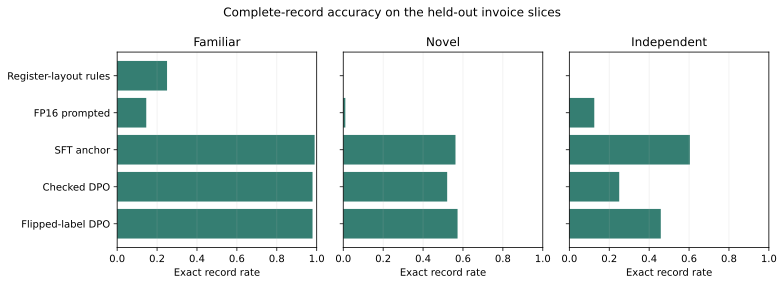

{"arm": "Register-layout rules", "generation": {"key": "SF-235300", "split": "novel", "family": "novel-01", "completed": false, "answer": null, "reference": {"invoice_id": "SF-235300", "issued_on": "2025-02-20", "supplier": "Sample Supplier 3219", "currency": "GBP", "line_items": [{"description": "Rack inspection", "quantity": 8, "unit_minor": 13740}], "subtotal_minor": 109920, "tax_minor": 14290, "total_minor": 124311}, "valid": false, "exact": false, "fields": 0.0, "field_correct": {"invoice_id": false, "issued_on": false, "supplier": false, "currency": false, "subtotal_minor": false, "tax_minor": false, "total_minor": false}, "row_f1": 0.0}, "pair_ranking": null}
{"arm": "FP16 prompted", "generation": {"key": "SF-235300", "split": "novel", "family": "novel-01", "completed": true, "answer": "{\"invoice_id\":\"SF-235300\",\"issued_on\":\"2025-02-20\",\"supplier\":\"Sample Supplier 3219\",\"currency\":\"GBP\",\"line_items\":[],\"subtotal_minor\":124311,\"tax_minor\":109920,\"total_mino

In [13]:
comparisons = [
    ("SFT anchor", "Checked DPO"),
    ("SFT anchor", "Flipped-label DPO"),
    ("Flipped-label DPO", "Checked DPO"),
]
held_rankings, preference_summary = measure_preferences(held_pair_items, held_logps, comparisons)
(RESULTS / "03-held-rankings.json").write_text(
    json.dumps(held_rankings, indent=2) + "\n", encoding="utf-8",
)
expected_roster = [(row.key, row.split, row.family) for row in evaluation_items]
for name, observed in scores.items():
    if [(row["key"], row["split"], row["family"]) for row in observed] != expected_roster:
        raise RuntimeError(f"{name} did not generate on the fixed evaluation roster.")
matched_rows = {name: [row for row in rows if row["key"] in held_keys] for name, rows in scores.items()}
matched_generation = {
    name: {"exact": sum(row["exact"] for row in rows), "n": len(rows)} for name, rows in matched_rows.items()
}
matched_generation_intervals = {
    f"{candidate} minus {baseline}": paired_family_interval(matched_rows[baseline], matched_rows[candidate])
    for baseline, candidate in comparisons
}
report = save_results(
    "03", scores, training, comparisons, catalogue_version=CATALOG_VERSION, packages=versions,
    anchor_sha256=anchor_digest, reference_sha256=reference_digest, split_sha256=manifest["sha256"],
    pair_audit_sha256=fingerprint(audits), schedule_sha256=schedule_sha256,
    adapters=adapters, initial_dpo_losses=initial_losses, matched_exposure=matched_exposure,
    settings={"batch_size": BATCH, "max_tokens": MAX_TOKENS, "max_new_tokens": MAX_NEW_TOKENS,
              "beta": BETA, "noise_fraction": NOISE_FRACTION, "anchor_lr": ANCHOR_LR, "dpo_lr": DPO_LR,
              "adapter_rank": 8, "adapter_alpha": 16, "adapter_targets": ["q_proj", "v_proj"],
              "sample": False, "beams": 1, "dtype": "fp16" if DEVICE == "cuda" else "float32"},
    actual_flips=sorted(flipped), excluded_train=excluded_train, excluded_held=excluded_held,
    held_out_preference=preference_summary, generation_exact_on_matched_pairs=matched_generation,
    matched_generation_intervals=matched_generation_intervals,
    shifted_gradient_evidence=mask_evidence, worked_invoice=WORKED_INVOICE,
    evaluation_seconds=evaluation_seconds, reference_scoring_seconds=reference_seconds,
)
for name, rows in scores.items():
    example = next(row for row in rows if row["key"] == WORKED_INVOICE)
    rank = next((row for row in held_rankings.get(name, []) if row["key"] == WORKED_INVOICE), None)
    print(json.dumps({"arm": name, "generation": example, "pair_ranking": rank}, ensure_ascii=False))
print("Evidence files:", ", ".join(str(path) for path in sorted(RESULTS.glob("03-*.*"))))

## Read the result

First compare verified-candidate wins and exact generated records. Check whether the
arms differ across held-out slices and whether a change coincides with invalid JSON
or missing end markers. Then trace the remittance example from the input to the raw outputs.

The [DPO paper](https://arxiv.org/abs/2305.18290) derives the objective. The
[Together Cookbook](https://github.com/togethercomputer/post-training-cookbook/blob/226e03ca225d6f13434047cf0f45ab3070a29801/post_training_cookbook/dpo/loss.py)
informed the local response-masked implementation. [Read the lesson](https://docs.recohut.com/courses/advanced-llm-fine-tuning/2-compare-training-stages/03-audit-preference-pairs).